In [1]:
import strahler
from importlib.metadata import version as package_version

package = package_version("strahler")
library = strahler.version()
if package != library:
    raise RuntimeError("Package/library version mismatch. Reinstall strahler in this kernel, "
                       "check STRAHLER_LIB, and restart the kernel before continuing.")
print("strahler package and library versions match")

from notebook_support import HERE, table
from IPython.display import Markdown, SVG, display
from strahler.widgets import TreeView
from lexicographic_nester import (BACKENDS, RESULTS, manifest, pairs, host_svg,
                                  recorded_results, measure_case, check_agreement, run_all)

strahler package and library versions match


# Nester: keep the Strahler bound small

How far can we solve Nester games by giving the host more room before
allowing a higher Strahler number? Here, adaptive means trying every allowed
`t` at one `k`, then increasing `k` and starting `t` again at zero.

We compare `AD` (ordinary attractor-decomposition lifting) and `PM` (Strahler
progress-measure lifting), each with and without iterative shaving (`+iter`).
That gives four methods: `AD`, `AD+iter`, `PM`, and `PM+iter`.
We use every noncompact game in the archive, n=1 through n=7. These are the
original files without `_compact`; preprocessing and same-parity priority
compression are off.

In [2]:
games = manifest()
reference = recorded_results()
first = {row["backend"]: row for row in reference["rows"] if row["n"] == 1}
nester1 = games[0]
assert nester1["vertices"] == 22

## Start with the host trees

A host supplies the positions to which the solver can assign vertices. Each
attempt uses only the occupied part of its host for the returned tree. Nester-1 has 22 vertices,
so we can still draw its complete hosts at a readable size.

We write a host as $U^k_{t,h}$:

| Parameter | Meaning |
|---|---|
| $k$ | Allowed Strahler number. A chain has Strahler number 1. |
| $t$ | Size allowance. Increasing it makes room for more leaves. |
| $h$ | Number of node levels, including the root. |

AD prints these parameters as `K`, `t`, and `H`. PM uses `depth` for its
number of measure components, so its host has $h=\text{depth}+1$ node levels.
Each player has its own host; their heights can differ.

The drawings use the first successful pair for Nester-1. Shaving gives the
same pair on this instance. Numbers at the left count levels from the root;
edge labels are bitstrings, with $\varepsilon$ for an empty string.

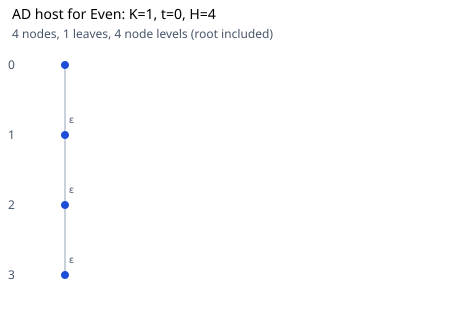

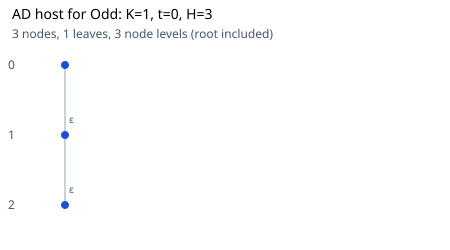

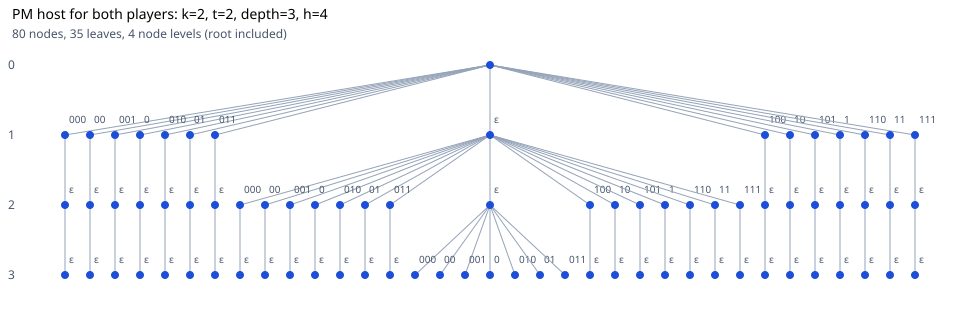

In [3]:
ad_parameters = first["AD"]["parameters"]
for player, parameters in zip(("Even", "Odd"), ad_parameters):
    k, t, h = (parameters[key] for key in ("K", "t", "H"))
    display(SVG(host_svg(k, t, h, f"AD host for {player}: K={k}, t={t}, H={h}")))

pm_parameters = first["PM"]["parameters"]
assert pm_parameters[0] == pm_parameters[1]
k, t, depth = (pm_parameters[0][key] for key in ("k", "t", "depth"))
display(SVG(host_svg(k, t, depth + 1,
                    f"PM host for both players: k={k}, t={t}, depth={depth}, h={depth + 1}")))

The AD drawings show the base tree $U^K_{t,H}$. AD lifting also adds lazy
positions between branches and a TOP position outside the tree. PM uses the
bitstrings along a root-to-leaf path as the components of a measure.

AD finishes Nester-1 with a chain at `(K,t)=(1,0)`. PM needs `(k,t)=(2,2)`;
its host has 35 leaves for a game of 22 vertices. The spare positions let
one host accommodate different possible answers.

## The trees used in the answer

Even wins all 22 vertices of Nester-1, so Odd's answer tree is empty.
These occupied trees are smaller than the hosts above. AD node labels show
priority bounds on the solver's normalized scale.

For `PM+iter`, the last tree covers the vertices left after earlier rounds.
Those earlier wins still count toward the answer.

AD: Even's occupied tree at the final pair.

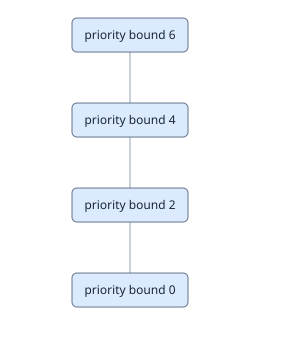

PM: Even's occupied tree at the final pair.

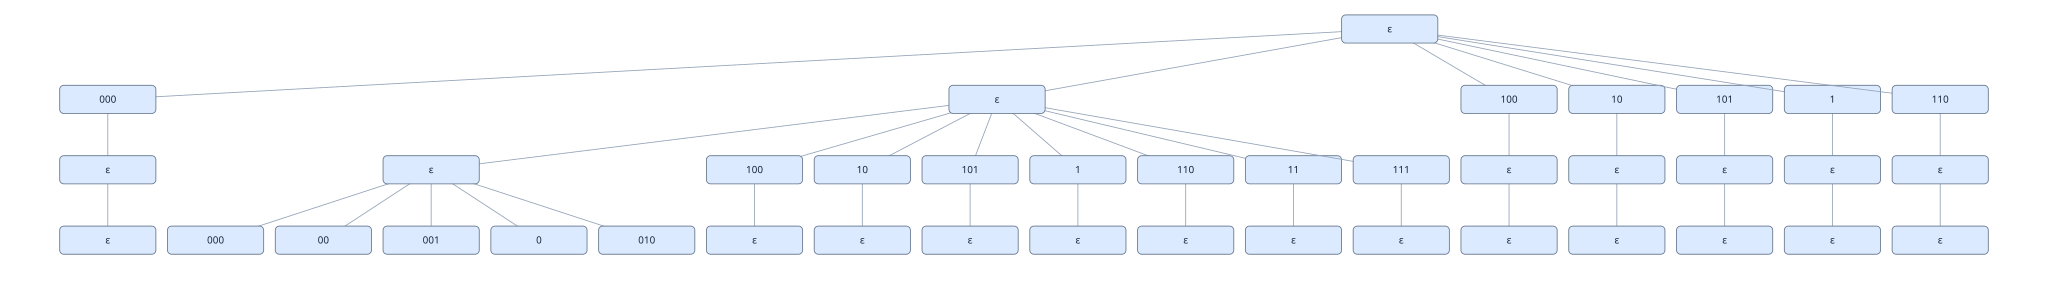

PM+iter: Even's occupied tree at the final pair.

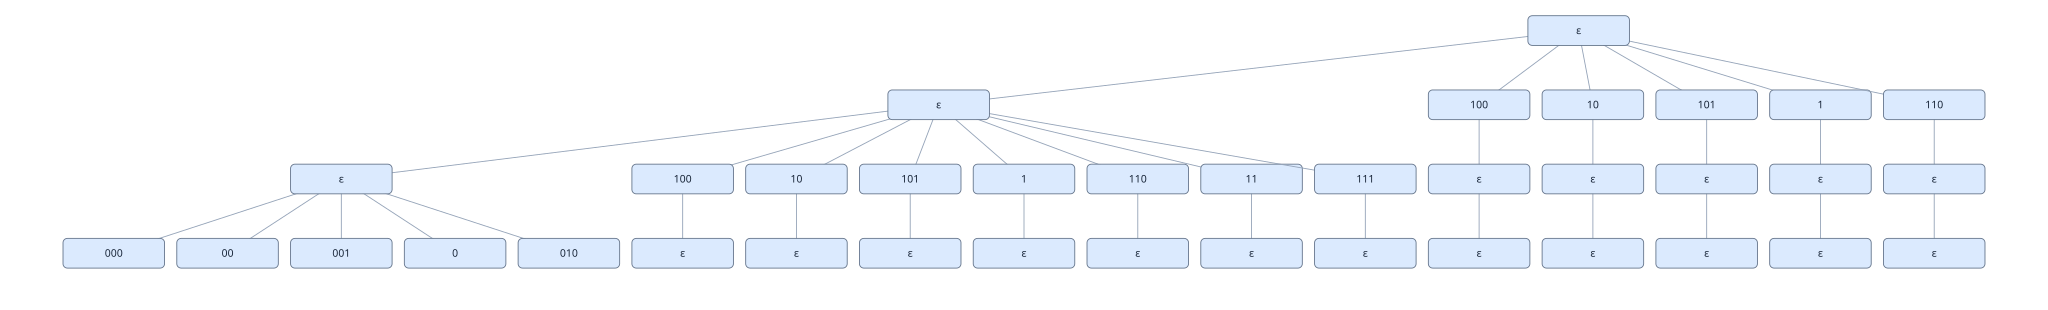

In [4]:
def label_priorities(node):
    if node is None:
        return None
    return dict(node, label=f"priority bound {node['h']}",
                children=[label_priorities(child) for child in node['children']])

for backend in ("AD", "PM", "PM+iter"):
    example = first[backend]["example"]
    tree = (label_priorities(example["trees"][0]) if backend == "AD"
            else example["rounds"][-1]["trees"][0]["tree"])
    display(Markdown(f"{backend}: Even's occupied tree at the final pair."))
    display(TreeView(tree, mode="tree", edges=False))

## Where the caps come from

Let $N$ be the number of game vertices; n is the Nester instance number.
A certificate tree has at most $N$ occupied leaves. For a tree of height $h$
with at most $N$ leaves, [Proposition 3](https://arxiv.org/html/2003.08627)
gives $\operatorname{Str}(T)\leq\min(h,\lfloor\log_2 N\rfloor+1)$.
A one-node tree has Strahler number 1, which accounts for the extra 1.

[Lemma 16](https://arxiv.org/html/2003.08627) says that
$U^k_{\lfloor\log_2 N\rfloor,h}$ accommodates every tree with at most $N$
leaves, height at most $h$, and Strahler number at most $k$. We therefore try

$$0\leq t\leq t_{\max}=\lfloor\log_2 N\rfloor,
\qquad 1\leq k\leq k_{\max}=\min(h,t_{\max}+1).$$

For AD, $h=H$. For PM, $h=\text{depth}+1$, including the root; its tree
also has at most $N$ occupied leaves
([Theorem 26](https://arxiv.org/html/2003.08627)). Both variants keep these
initial caps throughout the walk, even when shaving removes vertices.
E/O in the tables means Even/Odd.

The cap on $t$ guarantees room for all certificates of that size and Strahler
bound. The host itself can have more than $N$ leaves.

In [5]:
def eo(values):
    return " / ".join(map(str, values))

table(["Nester n", "vertices N", "t cap", "AD height E/O", "PM height E/O",
       "AD K cap E/O", "PM k cap E/O"],
      [[g["n"], g["vertices"], g["t_max"], eo(g["AD_height"]),
        eo([d + 1 for d in g["PM_depth"]]), eo(g["AD_k_max"]), eo(g["PM_k_max"])]
       for g in games])

Nester n,vertices N,t cap,AD height E/O,PM height E/O,AD K cap E/O,PM k cap E/O
1,22,4,4 / 3,4 / 4,4 / 3,4 / 4
2,365,8,6 / 5,6 / 6,6 / 5,6 / 6
3,3029,11,8 / 7,8 / 8,8 / 7,8 / 8
4,14053,13,9 / 8,9 / 9,9 / 8,9 / 9
5,62707,15,10 / 9,10 / 10,10 / 9,10 / 10
6,259455,17,11 / 10,11 / 11,11 / 10,11 / 11
7,1021740,19,12 / 11,12 / 12,12 / 11,12 / 12


## The order of attempts

Nester-1 has $t_{\max}=4$, so its walk starts
`(1,0), (1,1), (1,2), (1,3), (1,4), (2,0), (2,1), ...`.
We stop at the first complete answer. Each player's effective `k` is capped
by its own host height.

Without `+iter`, each pair starts on the whole game. With `+iter`, certified
winning regions and their attractors leave the game before the next pair.
AD solves for both players before removing their regions. PM removes Even's
region before solving for Odd, following the existing shaving implementation.
Each attempt starts its finite labels from the bottom of the new host.

Both APIs select this walk with `search="lexicographic"`.

In [6]:
table(["k", "t values, in order"],
      [[k, ", ".join(str(t) for kk, t in pairs(22, 4) if kk == k)]
       for k in range(1, 5)])

k,"t values, in order"
1,"0, 1, 2, 3, 4"
2,"0, 1, 2, 3, 4"
3,"0, 1, 2, 3, 4"
4,"0, 1, 2, 3, 4"


## Results for all seven games

Each game and method gets 30 seconds total, including loading and all
parameter attempts. Linux also enforces a 2 GiB address-space limit. Workers
run one at a time. AD has no separate leaf-count cutoff; its hosts grow
within the memory allowance.

The saved run covers all 28 cases. Cells in the first table show the first
successful `(k,t)` and elapsed time, or the time limit if the run did not
finish. The second table gives the successful runs' parameters and wins.

Normal notebook execution reads these results and repeats Nester-1 below.
The final cell can repeat all seven games, taking about 14 minutes if every
case uses its full allowance.

In [7]:
print("Recorded UTC:", reference["recorded_utc"])
print("Recorded solver:", reference["version"])
print("Current solver:", strahler.version())
print("Recorded machine:", reference["machine"])
check_agreement(reference["rows"])

by_case = {(r["n"], r["backend"]): r for r in reference["rows"]}
def result_text(row):
    if row["outcome"] == "complete":
        return f"({row['k']},{row['t']}), {row['seconds']:.2f} s"
    return "30 s limit" if row["outcome"] == "timeout" else row["outcome"]

table(["Nester n", "vertices", *BACKENDS],
      [[g["n"], g["vertices"], *[result_text(by_case[g["n"], backend]) for backend in BACKENDS]]
       for g in games])

display(Markdown("Successful runs in more detail:"))
table(["Nester n", "method", "first (k,t)", "pairs tried", "seconds",
       "final tree Strahler E/O", "total wins E/O"],
      [[r["n"], r["backend"], (r["k"], r["t"]), r["attempts"], r["seconds"],
        eo(r["tree_strahler"]), eo(r["won"])]
       for r in reference["rows"] if r["outcome"] == "complete"])

Recorded UTC: 2026-11-10T11:09:45+00:00
Recorded solver: 0.4.2.dev4+g66c8037.dirty
Current solver: 0.4.2.dev4+g66c8037.dirty
Recorded machine: Linux x86_64, 4 CPUs


Nester n,vertices,AD,AD+iter,PM,PM+iter
1,22,"(1,0), 0.18 s","(1,0), 0.18 s","(2,2), 0.18 s","(2,2), 0.18 s"
2,365,"(2,1), 0.28 s","(1,1), 0.19 s","(3,2), 0.30 s","(3,2), 0.24 s"
3,3029,"(2,1), 3.50 s","(2,1), 2.17 s",30 s limit,30 s limit
4,14053,30 s limit,30 s limit,30 s limit,30 s limit
5,62707,30 s limit,30 s limit,30 s limit,30 s limit
6,259455,30 s limit,30 s limit,30 s limit,30 s limit
7,1021740,30 s limit,30 s limit,30 s limit,30 s limit


Successful runs in more detail:

Nester n,method,"first (k,t)",pairs tried,seconds,final tree Strahler E/O,total wins E/O
1,AD,"(1, 0)",1,0.1767,1 / 0,22 / 0
1,AD+iter,"(1, 0)",1,0.1779,1 / 0,22 / 0
1,PM,"(2, 2)",8,0.1783,2 / 0,22 / 0
1,PM+iter,"(2, 2)",8,0.18,2 / 0,22 / 0
2,AD,"(2, 1)",11,0.2797,2 / 1,325 / 40
2,AD+iter,"(1, 1)",2,0.1899,1 / 0,325 / 40
2,PM,"(3, 2)",21,0.2984,3 / 2,325 / 40
2,PM+iter,"(3, 2)",21,0.2358,3 / 0,325 / 40
3,AD,"(2, 1)",14,3.5002,2 / 1,1993 / 1036
3,AD+iter,"(2, 1)",14,2.1655,2 / 0,1993 / 1036


The pair shown for a completed run is the first successful `(k,t)` in this
order. `pairs tried` includes unsuccessful attempts and pairs that describe
the same host. A timed-out run has no successful pair to report.

`Total wins` includes vertices solved in earlier shaving rounds and their
attractors. `Final tree Strahler` measures the last occupied tree, which can
cover only part of the original winning region when shaving is on. Its final
`k` bounds the hosts used in that run; it does not prove the minimum Strahler
number of one tree for the whole original game.

In [8]:
largest = []
for backend in BACKENDS:
    solved = [r for r in reference["rows"]
              if r["backend"] == backend and r["outcome"] == "complete"]
    if solved:
        row = max(solved, key=lambda r: r["n"])
        largest.append([backend, row["n"], games[row["n"] - 1]["vertices"],
                        (row["k"], row["t"]), row["seconds"]])
    else:
        largest.append([backend, "none", "", "", ""])
table(["method", "largest solved n", "vertices", "final (k,t)", "seconds"], largest)

method,largest solved n,vertices,"final (k,t)",seconds
AD,3,3029,"(2, 1)",3.5002
AD+iter,3,3029,"(2, 1)",2.1655
PM,2,365,"(3, 2)",0.2984
PM+iter,2,365,"(3, 2)",0.2358


On Nester-2, AD finishes at `(2,1)` on the whole game and `(1,1)` with
shaving. Shaving combines certificates from different rounds, allowing a
smaller final host.

Keeping a low Strahler bound can be expensive: the solver must try larger
hosts before it can increase `k`. The time limits here measure this walk on
this machine; they do not establish an absolute limit on solving Nester games.

## Check the current build

Repeat all four Nester-1 runs with the current library, giving each five
seconds and the same memory allowance. Check the winning regions against
the saved run; execution times can differ.

In [9]:
live = [measure_case(nester1, backend, seconds=5, memory_gib=2) for backend in BACKENDS]
for row in live:
    assert row["outcome"] == "complete", row
    assert row["winner_sha256"] == first[row["backend"]]["winner_sha256"]
table(["method", "outcome", "first (k,t)", "seconds"],
      [[r["backend"], r["outcome"], (r["k"], r["t"]), r["seconds"]] for r in live])

method,outcome,"first (k,t)",seconds
AD,complete,"(1, 0)",0.1839
AD+iter,complete,"(1, 0)",0.1851
PM,complete,"(2, 2)",0.185
PM+iter,complete,"(2, 2)",0.1817


## Repeat the full run

Set `RUN_ALL` to `True` to repeat every noncompact instance with the same
30 s / 2 GiB allowance. A separate results file preserves the reference run.
Increase `SECONDS` to give unfinished cases more time.

In [10]:
RUN_ALL = False
SECONDS = 30
MEMORY_GIB = 2
if RUN_ALL:
    current = run_all(seconds=SECONDS, memory_gib=MEMORY_GIB,
                      output=HERE / "nester-lexicographic-current.json")

## Sources

The games are MLSolver validity games from Jeroen Keiren's
[Parity games dataset](https://doi.org/10.6084/m9.figshare.6004130.v1), under
CC0. It contains n=1 through n=7. The generator also requests n=8, but the
archive has no such file. The original compressed noncompact files and
their SHA-256 checksums are bundled in `nester/`.

The host construction and caps are from Daviaud, Jurdziński and Thejaswini,
[The Strahler Number of a Parity Game](https://arxiv.org/html/2003.08627),
Proposition 3, Lemma 16 and Theorem 26. The full recorded data are in
[lexicographic-results.json](nester/lexicographic-results.json).
[lexicographic_nester.py](lexicographic_nester.py) also runs the experiment
from the command line.